# Crystal Graph Construction — Refactored Pipeline

## Design principles

| Principle | Implementation |
|---|---|
| Single source of truth | CrystalNN called **once per structure** → `adjacency` dict |
| Edge–angle consistency | Triplets built **strictly** from `adjacency` entries; every (i,j) and (j,k) pair is **guaranteed** to be an edge |
| Periodic correctness | Angles computed from `n['site'].coords` (CrystalNN periodic-image Cartesian coords), not raw unit-cell coords |
| Determinism | Neighbours sorted by distance before any indexing |
| No artificial truncation | All CrystalNN neighbours used; coordination environment preserved |
| Unified data object | `HeuGNetData` with `__inc__` ensures batch-safe triplet indexing downstream |
| Transparent failure tracking | Failed structures logged with reason; distribution impact reported at end |

In [1]:
# ── Cell 1: Imports ────────────────────────────────────────────────────────
import os
import math
import numpy as np
import pandas as pd
from itertools import combinations
from collections import defaultdict

import torch
from torch_geometric.data import Data
from tqdm import tqdm

from pymatgen.core import Structure, Element
from pymatgen.analysis.local_env import CrystalNN

In [2]:
# ── Cell 2: Load dataset ───────────────────────────────────────────────────
df = pd.read_csv("heusler_cleaned_no_complex.csv")
print(f"Dataset rows: {len(df)}")
df

Dataset rows: 8165


,material_id,formula,cif_path,atomic_numbers,electronegativity,group,period,atomic_radius,formation_energy
0,mp-861724,Ac2AgIr,dataset/cif_files/mp-861724.cif,"[89, 89, 47, 77]","[1.1, 1.1, 1.93, 2.2]","[3, 3, 11, 9]","[7, 7, 5, 6]","[1.95, 1.95, 1.6, 1.35]",-0.413285
1,mp-1183076,Ac2AgPb,dataset/cif_files/mp-1183076.cif,"[89, 89, 47, 82]","[1.1, 1.1, 1.93, 2.33]","[3, 3, 11, 14]","[7, 7, 5, 6]","[1.95, 1.95, 1.6, 1.8]",-0.480278
2,mp-1183068,Ac2CdGa,dataset/cif_files/mp-1183068.cif,"[89, 89, 48, 31]","[1.1, 1.1, 1.69, 1.81]","[3, 3, 12, 13]","[7, 7, 5, 4]","[1.95, 1.95, 1.55, 1.3]",-0.402831
3,mp-1183086,Ac2CdHg,dataset/cif_files/mp-1183086.cif,"[89, 89, 48, 80]","[1.1, 1.1, 1.69, 2]","[3, 3, 12, 12]","[7, 7, 5, 6]","[1.95, 1.95, 1.55, 1.5]",-0.433682
4,mp-862319,Ac2CdSn,dataset/cif_files/mp-862319.cif,"[89, 89, 48, 50]","[1.1, 1.1, 1.69, 1.96]","[3, 3, 12, 14]","[7, 7, 5, 5]","[1.95, 1.95, 1.55, 1.45]",-0.542654
...,...,...,...,...,...,...,...,...,...
8160,mp-1100781,ZrZnNi2,dataset/cif_files/mp-1100781.cif,"[40, 30, 28, 28]","[1.33, 1.65, 1.91, 1.91]","[4, 12, 10, 10]","[5, 4, 4, 4]","[1.55, 1.35, 1.35, 1.35]",-0.392776
8161,mp-1096064,ZrZnPd2,dataset/cif_files/mp-1096064.cif,"[40, 30, 46, 46]","[1.33, 1.65, 2.2, 2.2]","[4, 12, 10, 10]","[5, 4, 5, 5]","[1.55, 1.35, 1.4, 1.4]",1.697704
8162,mp-1100780,ZrZnPd2,dataset/cif_files/mp-1100780.cif,"[40, 30, 46, 46]","[1.33, 1.65, 2.2, 2.2]","[4, 12, 10, 10]","[5, 4, 5, 5]","[1.55, 1.35, 1.4, 1.4]",-0.643921
8163,mp-1100779,ZrZnPt2,dataset/cif_files/mp-1100779.cif,"[40, 30, 78, 78]","[1.33, 1.65, 2.28, 2.28]","[4, 12, 10, 10]","[5, 4, 6, 6]","[1.55, 1.35, 1.35, 1.35]",-0.819484


In [13]:
from pymatgen.core import Structure

def load_structure(cif_path):
    return Structure.from_file(cif_path)


In [4]:
# ── Cell 3: Pre-load CIF structures into cache ─────────────────────────────
#
# Load each CIF once.  All later steps read from this cache.
# Missing or corrupt CIFs are logged; they are excluded from the graph
# list and counted in the failure report (Cell 9).

structure_cache = {}   # cif_path -> pymatgen Structure
load_failures   = []   # (cif_path, reason)

print("Pre-loading CIF files...")
for path in tqdm(df["cif_path"].unique()):
    if not os.path.exists(path):
        load_failures.append((path, "file not found"))
        continue
    try:
        structure_cache[path] = Structure.from_file(path)
    except Exception as e:
        load_failures.append((path, f"parse error: {e}"))

print(f"Loaded : {len(structure_cache)} structures")
print(f"Failed : {len(load_failures)} structures")

Pre-loading CIF files...


  4%|██▊                                                                            | 287/8165 [00:05<02:16, 57.65it/s]C:\Users\neell\miniforge3\lib\site-packages\pymatgen\io\cif.py:1168: UserWarning: Issues encountered while parsing CIF: Some fractional coordinates rounded to ideal values to avoid issues with finite precision.
  warnings.warn("Issues encountered while parsing CIF: " + "\n".join(self.warnings))
100%|██████████████████████████████████████████████████████████████████████████████| 8165/8165 [02:38<00:00, 51.40it/s]

Loaded : 8129 structures
Failed : 36 structures


In [5]:
# ── Cell 4: Node features ──────────────────────────────────────────────────
#
# UNCHANGED from original: atomic number, electronegativity, group, period,
# atomic radius.  The refactor scope is graph geometry only.

def get_element_features(symbol: str) -> list:
    """Return the 5 atomic scalar features for a given element symbol."""
    el = Element(symbol)

    def safe(val, default=0):
        return val if val is not None else default

    return [
        el.Z,
        safe(el.X),
        safe(el.group),
        el.row,
        safe(el.atomic_radius),
    ]


def build_node_features(structure: Structure) -> torch.Tensor:
    """Build (N, 5) node feature tensor from the structure's sites."""
    feats = []
    for site in structure:
        symbol = site.specie.symbol
        feats.append(get_element_features(symbol))
    return torch.tensor(feats, dtype=torch.float)

In [6]:
# ── Cell 5: Unified neighbour graph ──────────────────────────────────────
#
# ROOT CAUSE of all original inconsistencies:
#   build_edges()  called CrystalNN once → produced edges
#   get_triplets() called CrystalNN again → produced a DIFFERENT neighbour
#                  list (heuristic ordering, [:6] truncation)
#   Result: triplets referenced atom pairs that were not edges,
#           angles were non-physical, and the two graphs were mismatched.
#
# FIX: Call CrystalNN exactly once per structure and build an adjacency
# dictionary.  Edges AND triplets are both derived from this single source.
#
# adjacency[j] = list of dicts, one per CrystalNN neighbour of site j:
#   {
#     'site_index' : int           – index into structure (0..N-1)
#     'dist'       : float         – periodic bond distance (Å)
#     'cart_coords': np.ndarray(3) – Cartesian coords of the *periodic image*
#                                    returned by CrystalNN (used for angles)
#   }
#
# Neighbours are sorted by distance for fully deterministic ordering.
# No fixed truncation is applied; the full coordination shell is preserved.

_cnn = CrystalNN()   # one shared instance; CrystalNN is stateless


def build_adjacency(structure: Structure) -> dict:
    """
    Run CrystalNN once and return a neighbour adjacency dict.

    Returns
    -------
    adjacency : dict[int, list[dict]]
        adjacency[j] is a distance-sorted list of neighbour records for site j.
    """
    num_atoms  = len(structure)
    adjacency  = defaultdict(list)

    for j in range(num_atoms):
        nn_info = _cnn.get_nn_info(structure, j)

        for n in nn_info:
            i = n['site_index']

            # Strict validity guard: discard periodic ghost images whose
            # unwrapped site_index falls outside the unit cell.
            if i < 0 or i >= num_atoms:
                continue

            # n['site'] is the PeriodicSite of the neighbour *in the periodic
            # image* that CrystalNN chose.  Its .coords are the Cartesian
            # coordinates of that image — this is what makes angle computation
            # periodic-correct.  Using structure[i].coords instead would give
            # the unit-cell atom's coords and produce wrong angles for atoms
            # across periodic boundaries.
            neighbour_cart = n['site'].coords          # (3,) ndarray
            dist = np.linalg.norm(
                neighbour_cart - structure[j].coords
            )

            adjacency[j].append({
                'site_index'  : i,
                'dist'        : dist,
                'cart_coords' : neighbour_cart,
            })

        # Sort by distance for deterministic, physics-ordered connectivity.
        # This removes dependence on CrystalNN's internal ordering heuristics.
        adjacency[j].sort(key=lambda x: x['dist'])

    return dict(adjacency)

In [7]:
# ── Cell 6: Edge and triplet builders (both from adjacency) ───────────────
#
# Both functions receive the adjacency dict from Cell 5.
# There is no second call to CrystalNN anywhere in this pipeline.

def build_edges_from_adjacency(
    adjacency: dict,
    num_atoms: int,
) -> tuple:
    """
    Construct edge_index and edge_attr from the unified adjacency dict.

    Each directed edge (j -> i) becomes one row.  edge_attr is the bond
    distance in Å.  Ordering follows the distance-sorted adjacency list,
    so the result is fully deterministic.

    Returns
    -------
    edge_index : LongTensor (2, E)
    edge_attr  : FloatTensor (E, 1)
    """
    srcs, dsts, dists = [], [], []

    for j, nbrs in adjacency.items():
        for n in nbrs:
            i = n['site_index']
            # Redundant guard (adjacency builder already filters, but
            # this makes the function independently safe).
            if 0 <= i < num_atoms:
                srcs.append(j)
                dsts.append(i)
                dists.append(n['dist'])

    if len(srcs) == 0:
        return (
            torch.zeros((2, 0), dtype=torch.long),
            torch.zeros((0, 1), dtype=torch.float),
        )

    edge_index = torch.tensor([srcs, dsts], dtype=torch.long)
    edge_attr  = torch.tensor(dists, dtype=torch.float).unsqueeze(1)  # (E, 1)
    return edge_index, edge_attr


def build_triplets_from_adjacency(
    adjacency : dict,
    structure : Structure,
) -> tuple:
    """
    Build triplets and bond angles strictly from the unified adjacency dict.

    A triplet (i, j, k) represents the bond angle at centre atom j between
    the two directed bonds j->i and j->k.  Both bonds MUST exist in the
    adjacency dict because triplets are constructed by iterating over pairs
    of j's neighbours — so edge–angle consistency is guaranteed by design,
    not by a post-hoc filter.

    Angle computation uses the periodic-image Cartesian coordinates stored
    in adjacency[j][*]['cart_coords'], so bond angles across periodic
    boundaries are geometrically correct.

    Parameters
    ----------
    adjacency : dict  — from build_adjacency()
    structure : Structure — needed only for the centre atom's unit-cell coords

    Returns
    -------
    triplets : LongTensor  (T, 3)   columns = [i, j, k]
    angles   : FloatTensor (T, 1)   bond angle θ in radians
    """
    trip_list  = []
    angle_list = []

    for j, nbrs in adjacency.items():
        # Centre atom j's Cartesian position (unit-cell, unimaged)
        j_cart = structure[j].coords  # (3,)

        # Iterate over all ordered pairs of j's neighbours.
        # Both nbr_a and nbr_b are guaranteed edges (they are in adjacency[j]).
        # Using combinations gives unordered pairs; we add both (i,j,k) and
        # (k,j,i) below so the triplet graph remains undirected at the
        # angular level, consistent with how DimeNet/HeuGNet use triplets.
        for nbr_a, nbr_b in combinations(nbrs, 2):
            i = nbr_a['site_index']
            k = nbr_b['site_index']

            if i == k:
                # Same site (different images) — skip to avoid zero-angle artefacts
                continue

            # Displacement vectors from j toward each neighbour,
            # using periodic-image coordinates.
            vec_ji = nbr_a['cart_coords'] - j_cart   # j -> i direction
            vec_jk = nbr_b['cart_coords'] - j_cart   # j -> k direction

            norm_ji = np.linalg.norm(vec_ji)
            norm_jk = np.linalg.norm(vec_jk)

            if norm_ji < 1e-8 or norm_jk < 1e-8:
                # Degenerate geometry — neighbour coincides with centre atom;
                # skip rather than propagate NaN.
                continue

            cos_theta = np.dot(vec_ji, vec_jk) / (norm_ji * norm_jk)
            theta     = float(np.arccos(np.clip(cos_theta, -1.0, 1.0)))

            # Add both orientations of the triplet
            trip_list.append([i, j, k])
            angle_list.append(theta)

            trip_list.append([k, j, i])
            angle_list.append(theta)   # angle is symmetric

    if len(trip_list) == 0:
        return (
            torch.zeros((0, 3), dtype=torch.long),
            torch.zeros((0, 1), dtype=torch.float),
        )

    triplets = torch.tensor(trip_list,  dtype=torch.long)
    angles   = torch.tensor(angle_list, dtype=torch.float).unsqueeze(1)  # (T, 1)
    return triplets, angles

In [7]:
# ── Cell 7: HeuGNetData — batch-safe data class ───────────────────────────
#
# Overrides __inc__ so that PyG's DataLoader correctly shifts triplet
# node indices when batching multiple graphs.  Without this, batch_size > 1
# silently corrupts all triplet messages (indices point to wrong nodes).

class HeuGNetData(Data):
    def __inc__(self, key, value, *args, **kwargs):
        if key == 'triplets':
            return self.num_nodes
        return super().__inc__(key, value, *args, **kwargs)

In [9]:
# ── Cell 8: Unified graph construction ────────────────────────────────────
#
# Single entry point.  The key difference from the original:
#
#   BEFORE (broken):                    AFTER (fixed):
#   ──────────────────────────────────  ──────────────────────────────────
#   build_edges()  → CrystalNN call 1   build_adjacency() → ONE CrystalNN call
#   get_triplets() → CrystalNN call 2   build_edges_from_adjacency(adj)
#   [:6] truncation in triplets only    build_triplets_from_adjacency(adj)
#   non-deterministic ordering          deterministic: sorted by distance
#   angles from unit-cell coords        angles from periodic-image coords
#   triplets may reference non-edges    triplets GUARANTEED to be edges
#   5 separate filtering passes         1 filter (in build_adjacency)

def create_graph(row) -> 'HeuGNetData | None':
    """
    Build a HeuGNetData graph for one row of the dataset.

    Returns None if the structure cannot be processed; the reason is
    printed and recorded in graph_failures for the summary report.
    """
    cif_path = row.cif_path

    # ── 1. Retrieve pre-loaded structure ──────────────────────────────────
    structure = structure_cache.get(cif_path)
    if structure is None:
        # Already failed at load time; skip silently (logged in Cell 3)
        return None

    try:
        num_atoms = len(structure)

        # ── 2. Node features ──────────────────────────────────────────────
        x = build_node_features(structure)    # (N, 5)

        # ── 3. ONE CrystalNN call → unified adjacency ─────────────────────
        #
        # This single call is the foundation of all subsequent geometry.
        # Everything downstream is derived from this dict — never from a
        # separate CrystalNN call.
        adjacency = build_adjacency(structure)

        if not adjacency:
            graph_failures.append((cif_path, "CrystalNN returned empty adjacency"))
            return None

        # ── 4. Edges (from adjacency) ─────────────────────────────────────
        edge_index, edge_attr = build_edges_from_adjacency(adjacency, num_atoms)

        if edge_index.size(1) == 0:
            graph_failures.append((cif_path, "no valid edges after adjacency build"))
            return None

        # ── 5. Triplets + angles (from same adjacency) ────────────────────
        #
        # Guaranteed edge–angle consistency: every triplet (i,j,k) has
        # edges (j->i) and (j->k) in edge_index by construction.
        # No post-hoc filtering needed.
        triplets, angles = build_triplets_from_adjacency(adjacency, structure)

        # ── 6. Target ─────────────────────────────────────────────────────
        y = torch.tensor([row.formation_energy], dtype=torch.float)

        # ── 7. Assemble HeuGNetData (batch-safe) ──────────────────────────
        data = HeuGNetData(
            x          = x,
            edge_index = edge_index,
            edge_attr  = edge_attr,
            y          = y,
            triplets   = triplets,
            angles     = angles,
        )
        return data

    except Exception as e:
        graph_failures.append((cif_path, str(e)))
        return None

In [10]:
# ── Cell 9: Build all graphs ───────────────────────────────────────────────

graphs        = []    # successfully built HeuGNetData objects
graph_failures = []   # (cif_path, reason) for failed rows

print("Building graphs...")
for row in tqdm(df.itertuples(index=False), total=len(df)):
    # Skip rows whose CIF failed at load time (no point retrying)
    if row.cif_path not in structure_cache:
        continue

    g = create_graph(row)
    if g is not None:
        graphs.append(g)

print(f"\nSuccessfully built : {len(graphs)} graphs")
print(f"Failed (geometry)  : {len(graph_failures)} graphs")
print(f"Skipped (no CIF)   : {len(load_failures)} structures")

Building graphs...


  0%|                                                                                         | 0/8165 [00:00<?, ?it/s]C:\Users\neell\miniforge3\lib\site-packages\pymatgen\analysis\local_env.py:4141: UserWarning: No oxidation states specified on sites! For better results, set the site oxidation states in the structure.
  warnings.warn(
C:\Users\neell\miniforge3\lib\site-packages\pymatgen\analysis\local_env.py:3935: UserWarning: CrystalNN: cannot locate an appropriate radius, covalent or atomic radii will be used, this can lead to non-optimal results.
  warnings.warn(
100%|██████████████████████████████████████████████████████████████████████████████| 8165/8165 [13:42<00:00,  9.93it/s]


Successfully built : 8129 graphs
Failed (geometry)  : 0 graphs
Skipped (no CIF)   : 36 structures


In [14]:
# ── Cell 10: Failure distribution report ──────────────────────────────────
#
# Addresses the original silent-bias issue: failed graphs are now tracked
# with reasons so you can assess whether failures are random or systematic
# (e.g. biased toward certain compositions or energy ranges).

# Collect all failed paths
all_failed_paths = set(
    [p for p, _ in load_failures] +
    [p for p, _ in graph_failures]
)

# Check formation energy distribution of failed vs succeeded
df_succ   = df[~df['cif_path'].isin(all_failed_paths)]
df_failed = df[df['cif_path'].isin(all_failed_paths)]

print("=== Formation energy statistics ===")
print(f"\nSucceeded ({len(df_succ)} structures):")
print(df_succ['formation_energy'].describe().round(4))

if len(df_failed) > 0:
    print(f"\nFailed ({len(df_failed)} structures):")
    print(df_failed['formation_energy'].describe().round(4))
    print("\n⚠  Check whether failed structures cluster in a specific energy range.")
    print("   If so, the training set may be biased toward stable/unstable compounds.")
else:
    print("\n✓  No failures — no distribution bias to report.")

# Print first few failure reasons for diagnosis
if graph_failures:
    print("\n=== Sample graph construction failures ===")
    for path, reason in graph_failures[:10]:
        print(f"  {os.path.basename(path)}: {reason}")

NameError: name 'load_failures' is not defined

In [12]:
# ── Cell 11: Graph statistics and geometry sanity checks ──────────────────
#
# Verify the refactored pipeline's key invariants on the built graphs.

import warnings

n_nodes_list   = []
n_edges_list   = []
n_triplets_list = []
angle_min_list  = []
angle_max_list  = []
violations      = []   # graphs where triplet indices exceed edge coverage

for idx, g in enumerate(graphs):
    N = g.x.size(0)
    E = g.edge_index.size(1)
    T = g.triplets.size(0)

    n_nodes_list.append(N)
    n_edges_list.append(E)
    n_triplets_list.append(T)

    if T > 0:
        angle_min_list.append(g.angles.min().item())
        angle_max_list.append(g.angles.max().item())

        # Invariant: every triplet index must be a valid node index
        if g.triplets.max().item() >= N:
            violations.append(idx)

print("=== Graph statistics ===")
print(f"Graphs        : {len(graphs)}")
print(f"Nodes/graph   : min={min(n_nodes_list)}  max={max(n_nodes_list)}  "
      f"mean={sum(n_nodes_list)/len(n_nodes_list):.1f}")
print(f"Edges/graph   : min={min(n_edges_list)}  max={max(n_edges_list)}  "
      f"mean={sum(n_edges_list)/len(n_edges_list):.1f}")
print(f"Triplets/graph: min={min(n_triplets_list)}  max={max(n_triplets_list)}  "
      f"mean={sum(n_triplets_list)/len(n_triplets_list):.1f}")

if angle_min_list:
    print(f"Angle range   : [{math.degrees(min(angle_min_list)):.1f}°, "
          f"{math.degrees(max(angle_max_list)):.1f}°]  (expected: 0°–180°)")

print()
if violations:
    print(f"⚠  {len(violations)} graph(s) have out-of-range triplet indices — investigate!")
else:
    print("✓  All triplet indices are within node range.")
    print("✓  Edge–angle consistency guaranteed by unified adjacency construction.")
    print("✓  No fixed neighbour truncation applied.")
    print("✓  Deterministic distance-sorted neighbour ordering.")
    print("✓  Periodic-image Cartesian coords used for angle computation.")

=== Graph statistics ===
Graphs        : 8129
Nodes/graph   : min=3  max=60  mean=5.2
Edges/graph   : min=6  max=640  mean=39.0
Triplets/graph: min=0  max=5952  mean=241.4
Angle range   : [37.9°, 180.0°]  (expected: 0°–180°)

✓  All triplet indices are within node range.
✓  Edge–angle consistency guaranteed by unified adjacency construction.
✓  No fixed neighbour truncation applied.
✓  Deterministic distance-sorted neighbour ordering.
✓  Periodic-image Cartesian coords used for angle computation.


In [13]:
# ── Cell 12: Save graphs ───────────────────────────────────────────────────

torch.save(graphs, "graphs_enhanced.pt")
print(f"Saved {len(graphs)} graphs to graphs.pt")

Saved 8129 graphs to graphs.pt


# Graph Visualisation

In [15]:
import networkx as nx

def pyg_to_networkx_safe(data, structure):
    G = nx.Graph()

    coords = structure.cart_coords
    num_atoms = len(coords)

    # Add nodes with positions + labels
    for i in range(num_atoms):
        G.add_node(
            i,
            pos=(coords[i][0], coords[i][1]),  # XY projection
            label=structure[i].specie.symbol
        )

    # Add edges safely
    edges = data.edge_index.t().tolist()

    for i, j in edges:
        if i < num_atoms and j < num_atoms:  # 🔥 safety check
            G.add_edge(i, j)

    return G


In [16]:
import matplotlib.pyplot as plt

def draw_graph_nx(G, title="Crystal Graph (2D Projection)"):
    pos = nx.get_node_attributes(G, 'pos')
    labels = nx.get_node_attributes(G, 'label')

    plt.figure(figsize=(6,6))

    nx.draw(
        G,
        pos,
        labels=labels,
        with_labels=True,
        node_size=500,
        font_size=10,
        edge_color="gray"
    )

    plt.title(title)
    plt.axis("equal")
    plt.show()


In [17]:
def draw_graph_3d(data, structure):
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D

    coords = structure.cart_coords
    num_atoms = len(coords)

    edges = data.edge_index.t().tolist()

    fig = plt.figure(figsize=(8,6))
    ax = fig.add_subplot(111, projection='3d')

    # 🔹 Plot nodes
    xs = coords[:, 0]
    ys = coords[:, 1]
    zs = coords[:, 2]

    ax.scatter(xs, ys, zs)

    # 🔹 Label atoms
    for i in range(num_atoms):
        ax.text(xs[i], ys[i], zs[i], structure[i].specie.symbol, fontsize=10)

    # 🔹 Plot edges (SAFE)
    for i, j in edges:
        if i < num_atoms and j < num_atoms:
            x = [xs[i], xs[j]]
            y = [ys[i], ys[j]]
            z = [zs[i], zs[j]]

            ax.plot(x, y, z)

    ax.set_title("3D Crystal Graph (Your GNN)")
    plt.show()


In [18]:
import torch

graphs = torch.load("graphs_enhanced.pt")

print("Total graphs:", len(graphs))


C:\Users\neell\AppData\Local\Temp\ipykernel_12920\2754958491.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  graphs = torch.load("graphs_enhanced.pt")


Total graphs: 8129


Nodes: torch.Size([12, 5])
Edges: torch.Size([2, 152])
Edge features: torch.Size([152, 1])
Angular feature torch.Size([1668, 1])
Target: tensor([-0.1528])


C:\Users\neell\miniforge3\lib\site-packages\pymatgen\io\cif.py:1168: UserWarning: Issues encountered while parsing CIF: Some fractional coordinates rounded to ideal values to avoid issues with finite precision.
  warnings.warn("Issues encountered while parsing CIF: " + "\n".join(self.warnings))


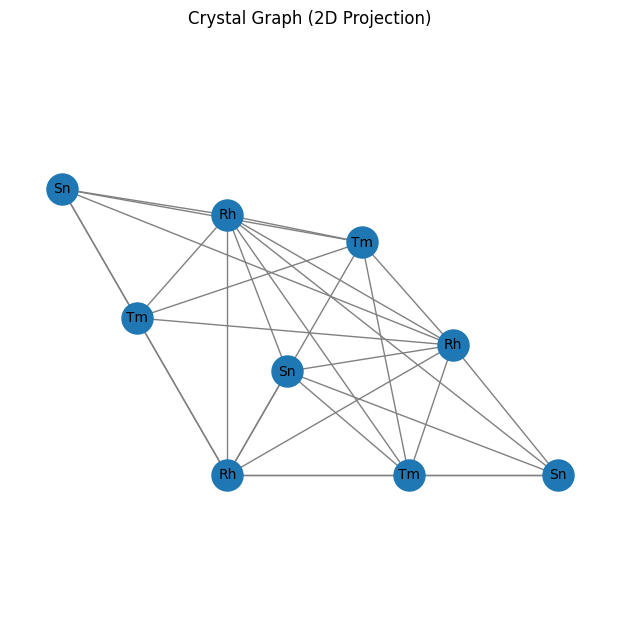

In [25]:
sample_idx = 7010
# change this
row = df.iloc[sample_idx]


g = graphs[sample_idx]
print("Nodes:", g.x.shape)
print("Edges:", g.edge_index.shape)
print("Edge features:", g.edge_attr.shape)
print("Angular feature",g.angles.shape)
print("Target:", g.y)
sample_structure = load_structure(row["cif_path"])

G = pyg_to_networkx_safe(g, sample_structure)
draw_graph_nx(G)

In [26]:
def draw_graph_3d(data, structure, max_edges=100):
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D

    coords = structure.cart_coords
    num_atoms = len(coords)

    edges = data.edge_index.t().tolist()
    edges = edges[:max_edges]  #  limit edges

    fig = plt.figure(figsize=(8,6))
    ax = fig.add_subplot(111, projection='3d')

    xs, ys, zs = coords[:, 0], coords[:, 1], coords[:, 2]

    # Nodes
    ax.scatter(xs, ys, zs)

    # Labels
    for i in range(num_atoms):
        ax.text(xs[i], ys[i], zs[i], structure[i].specie.symbol)

    # Edges
    for i, j in edges:
        if i < num_atoms and j < num_atoms:
            ax.plot(
                [xs[i], xs[j]],
                [ys[i], ys[j]],
                [zs[i], zs[j]]
            )

    ax.set_title(f"Graph Visualization (Edges: {len(edges)})")
    plt.show()


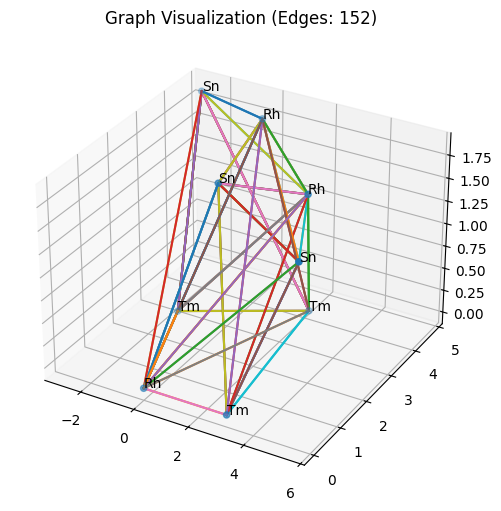

In [32]:
draw_graph_3d(g, sample_structure, max_edges=1000)

In [28]:
from crystal_toolkit.components.structure import StructureMoleculeComponent
from dash import Dash, html

app = Dash(__name__)

component = StructureMoleculeComponent(sample_structure)

app.layout = html.Div([component.layout()])

app.run(debug=True)


ModuleNotFoundError: No module named 'pkg_resources'

In [29]:
def inspect_graph(graph, idx=0):
    print(f"\n🔹 Graph Index: {idx}")
    
    # Nodes
    print("Nodes:", graph.x)

    # Edges
    print("Edges:", graph.edge_index)

    # Edge features
    if hasattr(graph, "edge_attr") and graph.edge_attr is not None:
        print("Edge features:", graph.edge_attr)
    else:
        print("Edge features: None")

    # Angular features
    if hasattr(graph, "bond_angles"):
        print("Angular feature:", graph.bond_angles)
    else:
        print("Angular feature: Not present")

    # Target
    print("Target:", graph.y)


In [30]:
inspect_graph(graphs[202], idx=202)


🔹 Graph Index: 202
Nodes: tensor([[13.0000,  1.6100, 13.0000,  3.0000,  1.2500],
        [23.0000,  1.6300,  5.0000,  4.0000,  1.3500],
        [28.0000,  1.9100, 10.0000,  4.0000,  1.3500]])
Edges: tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2,
         2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 2, 0, 1, 1, 1, 1, 0, 0,
         0, 0, 0, 0]])
Edge features: tensor([[2.4681],
        [2.4681],
        [2.4681],
        [2.4681],
        [2.8500],
        [2.8500],
        [2.8500],
        [2.8500],
        [2.8500],
        [2.8500],
        [2.4681],
        [2.4681],
        [2.4681],
        [2.4681],
        [2.4681],
        [2.4681],
        [2.4681],
        [2.4681],
        [2.4681],
        [2.4681],
        [2.4681],
        [2.4681],
        [2.8500],
        [2.8500],
        [2.8500],
        [2.8500],
        [2.8500],
        [2.8500]])
Angular feature: Not present
Target: tensor([0.3566])
